# PHÂN TÍCH VÀ DỰ ĐOÁN NHÂN VIÊN NGHỈ VIỆC

**Dữ liệu nghiên cứu:** IBM HR Analytics Employee Attrition (`LNT_NMT.csv`) — gồm **1.470 nhân viên** và **35 thuộc tính**.

> **Lưu ý quan trọng về dữ liệu:** Đây là bộ dữ liệu **mô phỏng (synthetic dataset)** do các nhà khoa học dữ liệu của IBM tạo ra nhằm mục đích nghiên cứu và học tập, không phải dữ liệu hồ sơ nhân sự thực tế từ một doanh nghiệp cụ thể. Đề tài sử dụng bộ dữ liệu này để xây dựng một **quy trình khai phá dữ liệu và học máy chuẩn mực, hoàn chỉnh và khép kín** (Làm sạch → Khám phá EDA → Kiểm định thống kê → Phân tích cơ chế tác động Trực tiếp / Gián tiếp → Tiền xử lý chống rò rỉ dữ liệu → Mô hình cơ sở & Mô hình nâng cao → Tối ưu siêu tham số & Đánh giá công bằng bằng Nested Cross-Validation → Ứng dụng chấm điểm rủi ro cho HR). Quy trình này có thể tái sử dụng nguyên vẹn cho dữ liệu nhân sự thực tế của doanh nghiệp chỉ bằng cách thay thế nguồn dữ liệu đầu vào và cập nhật danh mục cột.

---

## 1. Giới thiệu đề tài

1. **Mục tiêu nghiên cứu:**
   - **Phân tích thống kê & Nghiệp vụ:** Xác định các yếu tố có mối liên hệ có ý nghĩa thống kê với tình trạng nghỉ việc (`Attrition`), đồng thời phân tách rõ thành hai nhóm theo khả năng can thiệp của doanh nghiệp: **nhóm yếu tố trực tiếp** (công ty có thể điều chỉnh qua chính sách lương, cấp bậc, làm thêm giờ, môi trường làm việc...) và **nhóm yếu tố gián tiếp** (đặc điểm nhân khẩu học và lịch sử nền của nhân viên như tuổi, tình trạng hôn nhân, khoảng cách đi làm...).
   - **Kiểm tra cơ chế tác động:** Phân tích mối tương quan chéo giữa nhóm yếu tố gián tiếp và trực tiếp; đánh giá thực nghiệm xem các đặc điểm nền (như tuổi, thâm niên) tác động đến quyết định nghỉ việc một cách độc lập hay thông qua các biến trung gian (như lương, cấp bậc).
   - **Xây dựng và so sánh mô hình dự đoán:** Thiết lập quy trình huấn luyện không rò rỉ dữ liệu (*data leakage-free pipeline*) từ các mô hình cơ sở (**Logistic Regression**, **Decision Tree**, **Random Forest**) đến các mô hình Gradient Boosting nâng cao (**XGBoost**, **LightGBM**) kết hợp tinh chỉnh siêu tham số (`RandomizedSearchCV`) và đánh giá khách quan bằng **Nested Cross-Validation**.
   - **Ứng dụng quản trị nhân sự (HR Analytics):** Xây dựng bảng phân tích đánh đổi theo ngưỡng xác suất (*threshold trade-off*), phân tầng rủi ro nhân sự và cung cấp hàm chấm điểm tự động (`score_employee`) cho nhân viên mới.

2. **Mô tả tổng quan nhóm thuộc tính (35 cột gốc):**
   - **Biến mục tiêu:** `Attrition` (`Yes` = Nghỉ việc, `No` = Ở lại).
   - **Nhóm thông tin cá nhân & nhân khẩu học:** `Age` (Tuổi), `Gender` (Giới tính), `MaritalStatus` (Tình trạng hôn nhân), `Education` (Trình độ học vấn: 1–5), `EducationField` (Chuyên ngành), `DistanceFromHome` (Khoảng cách từ nhà đến công ty).
   - **Nhóm công việc & đãi ngộ:** `Department` (Phòng ban), `JobRole` (Vị trí công việc), `JobLevel` (Cấp bậc: 1–5), `OverTime` (Làm thêm giờ: Yes/No), `BusinessTravel` (Tần suất đi công tác), `MonthlyIncome` (Thu nhập hàng tháng), `DailyRate`, `HourlyRate`, `MonthlyRate`, `PercentSalaryHike` (% tăng lương), `StockOptionLevel` (Quyền mua cổ phiếu: 0–3).
   - **Nhóm thái độ & mức độ hài lòng (thang điểm 1–4):** `JobSatisfaction` (Hài lòng công việc), `EnvironmentSatisfaction` (Hài lòng môi trường), `RelationshipSatisfaction` (Hài lòng quan hệ đồng nghiệp), `WorkLifeBalance` (Cân bằng công việc – cuộc sống), `JobInvolvement` (Mức độ gắn kết công việc), `PerformanceRating` (Đánh giá hiệu suất).
   - **Nhóm thâm niên & lịch sử làm việc:** `TotalWorkingYears` (Tổng số năm kinh nghiệm), `NumCompaniesWorked` (Số công ty từng làm việc), `YearsAtCompany` (Số năm tại công ty), `YearsInCurrentRole` (Số năm ở vị trí hiện tại), `YearsSinceLastPromotion` (Số năm từ lần thăng chức gần nhất), `YearsWithCurrManager` (Số năm làm việc với quản lý hiện tại), `TrainingTimesLastYear` (Số lần đào tạo năm qua).
   - **Nhóm định danh / hằng số hệ thống:** `EmployeeNumber` (Mã nhân viên), `EmployeeCount`, `Over18`, `StandardHours`.

---
## 2. Đọc và Khám phá dữ liệu sơ bộ

In [1]:
import os, warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr, kruskal, loguniform, randint, uniform
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay)

# Các thư viện này được cài ở ô ngay phía trên nếu môi trường chưa có.
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")

try:                                   # Chạy trên Google Colab: upload file CSV
    from google.colab import files
    import io
    uploaded = files.upload()
    path = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[path]))
except ImportError:                    # Chạy trên máy cá nhân: đọc file CSV cùng thư mục
    df = pd.read_csv("LNT_NMT.csv")

print(df.shape)
df.head()

Saving LNT_NMT.csv to LNT_NMT.csv
(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
df.info()
print("Số giá trị thiếu:", df.isna().sum().sum())
print("Số dòng trùng:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

**Nhận xét sơ bộ:**
- Bộ dữ liệu gồm đúng **1.470 dòng** và **35 cột** (26 cột kiểu số nguyên `int64` và 9 cột kiểu chuỗi phân loại).
- Dữ liệu hoàn toàn đầy đủ (**0 giá trị thiếu**) và không có bản ghi trùng lặp (**0 dòng trùng**).

---
## 3. Tiền xử lý dữ liệu: Loại bỏ cột dư thừa, Mã hóa biến và Chuẩn bị Pipeline

**Mục tiêu và Phương pháp:**
- Kiểm tra và xóa các bản ghi trùng lặp (nếu có).
- Rà soát các cột hằng số (chỉ có 1 giá trị duy nhất trên toàn bộ nhân viên nên không có khả năng phân biệt) và cột mã định danh (`EmployeeNumber`) để loại bỏ.
- Mã hóa biến mục tiêu `Attrition` sang dạng nhị phân (`Yes` $\rightarrow 1$, `No` $\rightarrow 0$) và kiểm tra phân phối lớp trước/sau khi mã hóa.
- Mã hóa One-Hot (`drop_first=True`) các biến phân loại, chuẩn hóa tên cột (thay khoảng trắng bằng `_` để tương thích với LightGBM), chia tập Train/Test phân tầng (`stratify=y, random_state=42`) **trước khi chuẩn hóa** và đóng gói `StandardScaler` trong `Pipeline` để chống rò rỉ dữ liệu (*data leakage*).

In [3]:
df = df.drop_duplicates()                      # xóa dòng trùng (dữ liệu này có 0 dòng trùng)
for c in df.columns:
    if df[c].nunique() == 1:
        print("Cột hằng số:", c, "=", df[c].iloc[0])
drop_cols = ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"]
df = df.drop(columns=drop_cols)
print("Còn lại", df.shape[1], "cột,", df.shape[0], "dòng")

# Tỷ lệ lớp TRƯỚC khi mã hóa
cnt = df["Attrition"].value_counts()
print("\nTrước khi mã hóa:")
print(pd.DataFrame({"Số lượng": cnt, "Tỷ lệ (%)": (cnt / len(df) * 100).round(1)}))

df["Attrition"] = (df["Attrition"] == "Yes").astype(int)   # Yes=1, No=0

# Tỷ lệ lớp SAU khi mã hóa
cnt = df["Attrition"].value_counts().sort_index()
print("\nSau khi mã hóa (0 = ở lại, 1 = nghỉ việc):")
print(pd.DataFrame({"Số lượng": cnt, "Tỷ lệ (%)": (cnt / len(df) * 100).round(1)}))

Cột hằng số: EmployeeCount = 1
Cột hằng số: Over18 = Y
Cột hằng số: StandardHours = 80
Còn lại 31 cột, 1470 dòng

Trước khi mã hóa:
           Số lượng  Tỷ lệ (%)
Attrition                     
No             1233       83.9
Yes             237       16.1

Sau khi mã hóa (0 = ở lại, 1 = nghỉ việc):
           Số lượng  Tỷ lệ (%)
Attrition                     
0              1233       83.9
1               237       16.1


In [4]:
X = pd.get_dummies(df.drop(columns="Attrition"), drop_first=True)   # one-hot, bỏ 1 nhóm để tránh bẫy biến giả
X.columns = [c.replace(" ", "_") for c in X.columns]                # chuẩn hóa tên cột (LightGBM không nhận khoảng trắng)
y = df["Attrition"]

# Chia train/test TRƯỚC khi chuẩn hóa để tránh rò rỉ dữ liệu (test không được "nhìn thấy" khi scale)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Tỷ lệ nghỉ việc train/test: {:.1%} / {:.1%}".format(y_train.mean(), y_test.mean()))

# Chỉ chuẩn hóa 14 cột liên tục. Không scale cột one-hot (0/1) và các cột thang thứ bậc
# (Education, JobSatisfaction, JobLevel, StockOptionLevel... được coi như biến số bình thường).
continuous_cols = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome", "MonthlyRate",
                   "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears", "TrainingTimesLastYear",
                   "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"]
print(len(continuous_cols), "cột liên tục được chuẩn hóa")

def make_pipe(model):
    # Scaler được fit CHỈ trên dữ liệu train (và chỉ trên train-fold khi cross-validation)
    prep = ColumnTransformer([("scale", StandardScaler(), continuous_cols)], remainder="passthrough")
    return Pipeline([("prep", prep), ("model", model)])

Train: (1176, 44) | Test: (294, 44)
Tỷ lệ nghỉ việc train/test: 16.2% / 16.0%
14 cột liên tục được chuẩn hóa


**Nhận xét sau tiền xử lý:**
- Dữ liệu sạch còn lại **31 cột** trên **1.470 dòng** (sau khi mã hóa One-Hot thu được ma trận đặc trưng `X` gồm **44 cột**; tập Train có `1.176` dòng, tập Test có `294` dòng).
- Tỷ lệ nghỉ việc chiếm **16,1%** (237 người nghỉ so với 1.233 người ở lại) $\rightarrow$ **dữ liệu mất cân bằng lớp**, nên các mô hình ở các bước sau sẽ được gán trọng số cân bằng (`class_weight="balanced"` hoặc `scale_pos_weight`) và đánh giá qua Recall, Precision, F1, ROC-AUC, PR-AUC thay vì chỉ nhìn vào Accuracy.

---
## 4. Phân tích khám phá dữ liệu (EDA)

**Mục tiêu và Ý nghĩa:**
- Trực quan hóa sự phân bố của nhãn `Attrition` và độ tuổi (`Age`).
- So sánh tỷ lệ nghỉ việc (%) giữa các nhóm nhân viên theo các biến phân loại quan trọng (`OverTime`, `BusinessTravel`, `MaritalStatus`, `Department`, `JobRole`).
- Đối chiếu trung bình và phân phối (qua *Boxplot*) của các biến định lượng chủ chốt giữa hai nhóm *Ở lại* và *Nghỉ việc*.

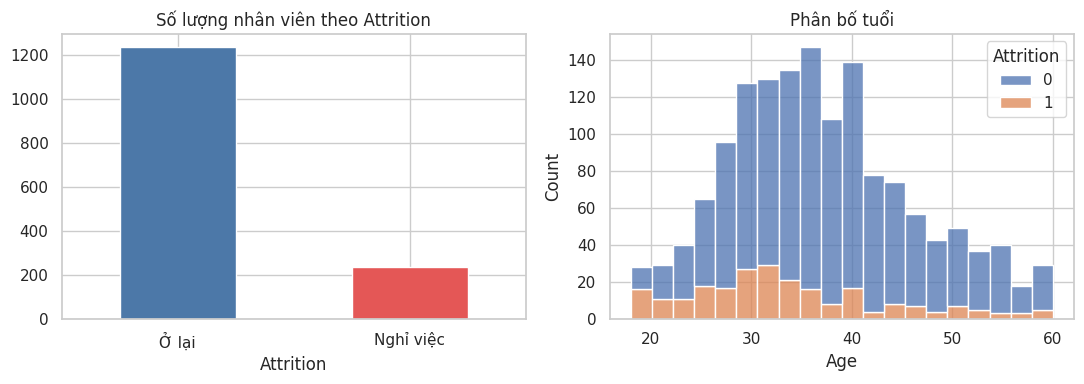

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["Attrition"].value_counts().sort_index().rename({0: "Ở lại", 1: "Nghỉ việc"}).plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"])
ax[0].set_title("Số lượng nhân viên theo Attrition"); ax[0].tick_params(axis="x", rotation=0)
sns.histplot(data=df, x="Age", hue="Attrition", multiple="stack", bins=20, ax=ax[1])
ax[1].set_title("Phân bố tuổi")
plt.tight_layout(); plt.show()

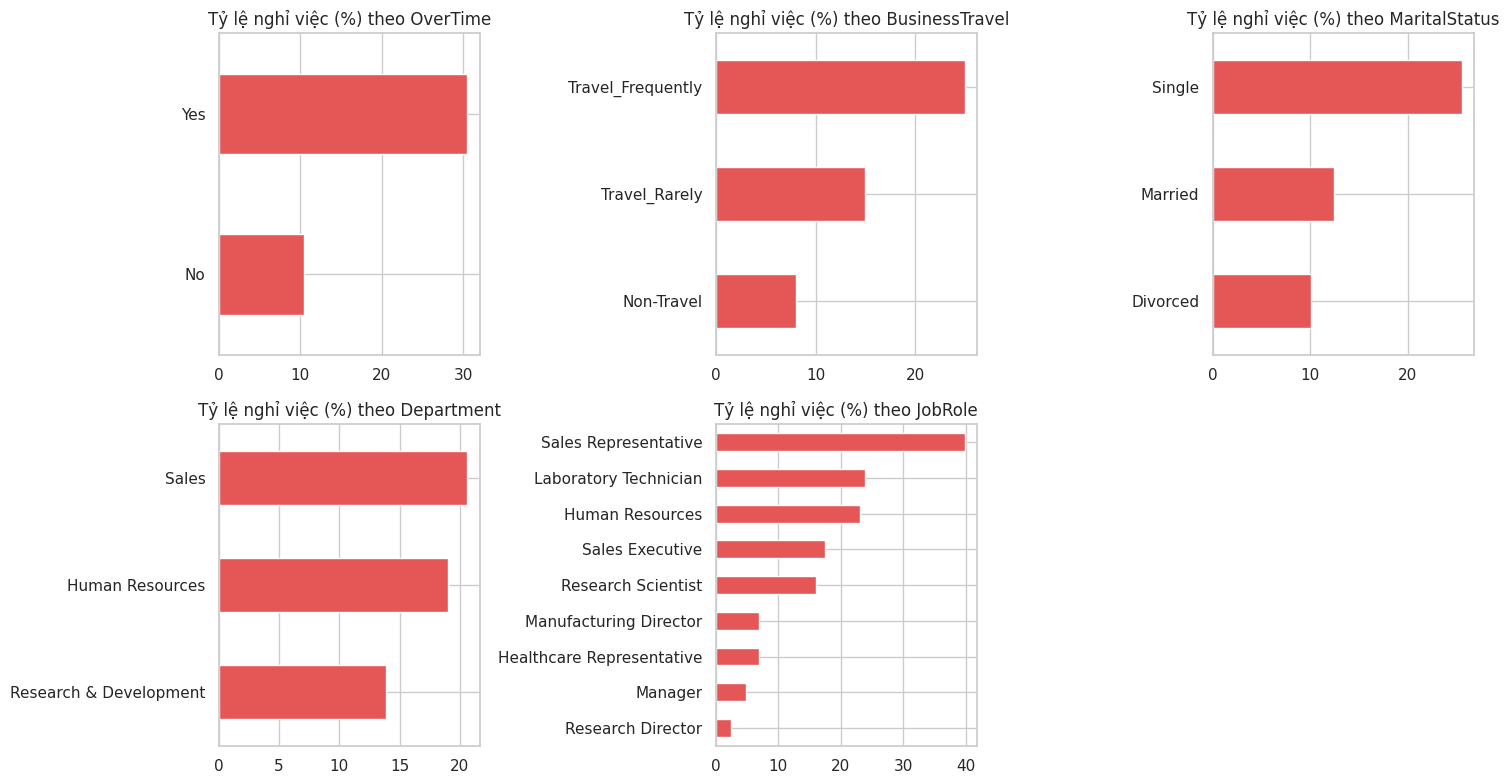

In [6]:
# Tỷ lệ nghỉ việc theo từng nhóm của các biến phân loại quan trọng
cat_cols = ["OverTime", "BusinessTravel", "MaritalStatus", "Department", "JobRole"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    (df.groupby(c)["Attrition"].mean() * 100).sort_values().plot.barh(ax=ax, color="#E45756")
    ax.set_title(f"Tỷ lệ nghỉ việc (%) theo {c}"); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

Attrition                  Ở lại  Nghỉ việc
Age                        37.56      33.61
MonthlyIncome            6832.74    4787.09
DistanceFromHome            8.92      10.63
TotalWorkingYears          11.86       8.24
YearsAtCompany              7.37       5.13
YearsSinceLastPromotion     2.23       1.95
JobSatisfaction             2.78       2.47


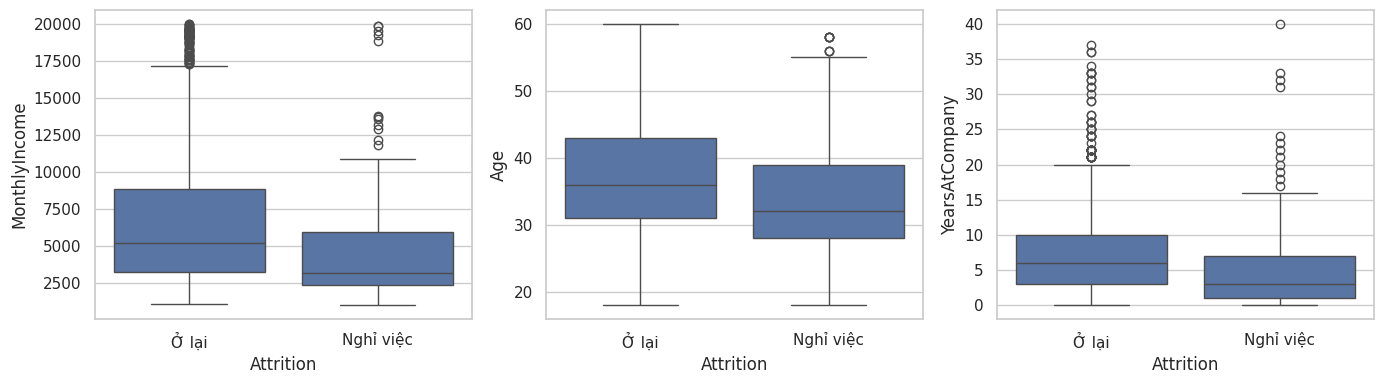

In [7]:
# Biến số: so sánh trung bình giữa nhóm nghỉ việc và ở lại
num_cols = ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears",
            "YearsAtCompany", "YearsSinceLastPromotion", "JobSatisfaction"]
print(df.groupby("Attrition")[num_cols].mean().round(2).T.rename(columns={0: "Ở lại", 1: "Nghỉ việc"}))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["MonthlyIncome", "Age", "YearsAtCompany"]):
    sns.boxplot(data=df, x="Attrition", y=c, ax=ax); ax.set_xticks([0, 1]); ax.set_xticklabels(["Ở lại", "Nghỉ việc"])
plt.tight_layout(); plt.show()

In [8]:
# Bảng chi tiết: số người, số người nghỉ và tỷ lệ nghỉ việc (%) theo từng nhóm
for c in ["Department", "BusinessTravel", "MaritalStatus", "JobRole", "JobLevel", "StockOptionLevel",
          "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "JobInvolvement", "OverTime"]:
    g = df.groupby(c)["Attrition"].agg(Tổng="count", Nghỉ="sum", TyLe="mean")
    g["TyLe"] = (g["TyLe"] * 100).round(1)
    print(c); print(g.rename(columns={"TyLe": "Tỷ lệ nghỉ (%)"}).to_string()); print()

# Thống kê mô tả các biến liên tục
cont = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome", "MonthlyRate", "NumCompaniesWorked",
        "PercentSalaryHike", "TotalWorkingYears", "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager"]
print(df[cont].describe().T[["mean", "std", "min", "50%", "max"]].round(1).to_string())

Department
                        Tổng  Nghỉ  Tỷ lệ nghỉ (%)
Department                                        
Human Resources           63    12            19.0
Research & Development   961   133            13.8
Sales                    446    92            20.6

BusinessTravel
                   Tổng  Nghỉ  Tỷ lệ nghỉ (%)
BusinessTravel                               
Non-Travel          150    12             8.0
Travel_Frequently   277    69            24.9
Travel_Rarely      1043   156            15.0

MaritalStatus
               Tổng  Nghỉ  Tỷ lệ nghỉ (%)
MaritalStatus                            
Divorced        327    33            10.1
Married         673    84            12.5
Single          470   120            25.5

JobRole
                           Tổng  Nghỉ  Tỷ lệ nghỉ (%)
JobRole                                              
Healthcare Representative   131     9             6.9
Human Resources              52    12            23.1
Laboratory Technician       259    62 

**Bảng chi tiết theo nhóm:** các tỷ lệ ở trên cho thấy rõ nhóm rủi ro cao: *Sales Representative* (39,8%), cấp bậc 1 (26,3%), không có cổ phiếu (24,4%), độc thân (25,5%), thường xuyên công tác (24,9%), làm thêm giờ (30,5%), cân bằng công việc – cuộc sống mức 1 (31,2%), gắn kết công việc mức 1 (33,7%). Nhóm rủi ro thấp nhất là *Research Director* (2,5%), *Manager* (4,9%) và cấp bậc 4 (4,7%). Lưu ý một số nhóm rất nhỏ (ví dụ `WorkLifeBalance = 1` chỉ có 80 người) nên tỷ lệ có độ dao động lớn.

**Nhận xét EDA (sẽ kiểm chứng thống kê ở Mục 5):**
- Nhân viên **làm thêm giờ (`OverTime = Yes`)** có tỷ lệ nghỉ việc cao hơn hẳn (~30,5% so với ~10,4%).
- Nhóm **độc thân (`Single`)** và **hay đi công tác (`Travel_Frequently`)** có tỷ lệ nghỉ việc cao hơn rõ rệt.
- Người nghỉ việc thường **trẻ hơn** (trung bình 33,61 so với 37,56 tuổi), **lương thấp hơn** (4.787 so với 6.833; dữ liệu không nêu đơn vị tiền tệ), **ít năm làm việc hơn** (8,24 so với 11,86 năm) và **ở xa công ty hơn** (10,63 so với 8,92).
- Vai trò *Sales Representative* có tỷ lệ nghỉ việc cao nhất (~40%).

---
## 5. Kiểm định thống kê mối liên hệ với nghỉ việc

### 5.1. Biến phân loại và thứ bậc – Kiểm định Chi-square ($\chi^2$)
Kiểm tra tính độc lập giữa từng biến phân loại/thứ bậc với `Attrition` ($p < 0,05 \rightarrow$ có liên hệ có ý nghĩa thống kê).

*Ghi chú:* danh sách biến trên là các biến nghiệp vụ được chọn; `Education`, `RelationshipSatisfaction`, `PerformanceRating` không đưa vào kiểm định.


In [9]:
rows = []
for c in ["OverTime", "BusinessTravel", "MaritalStatus", "Department", "JobRole",
          "EducationField", "Gender", "JobSatisfaction", "EnvironmentSatisfaction",
          "WorkLifeBalance", "JobInvolvement", "StockOptionLevel", "JobLevel"]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df[c], df["Attrition"]))
    rows.append((c, round(chi2, 1), p))
res = pd.DataFrame(rows, columns=["Biến", "Chi2", "p_value"]).sort_values("p_value")
res["Có ý nghĩa (p<0.05)"] = np.where(res["p_value"] < 0.05, "Có", "Không")
res["p_value"] = res["p_value"].map(lambda x: f"{x:.4f}")
res

,Biến,Chi2,p_value,Có ý nghĩa (p<0.05)
0,OverTime,87.6,0.0000,Có
4,JobRole,86.2,0.0000,Có
12,JobLevel,72.5,0.0000,Có
11,StockOptionLevel,60.6,0.0000,Có
2,MaritalStatus,46.2,0.0000,Có
10,JobInvolvement,28.5,0.0000,Có
1,BusinessTravel,24.2,0.0000,Có
8,EnvironmentSatisfaction,22.5,0.0001,Có
7,JobSatisfaction,17.5,0.0006,Có
9,WorkLifeBalance,16.3,0.0010,Có


In [10]:
# Hiệu chỉnh Holm cho 13 phép thử Chi-square ở Mục 5.1 (cùng cách làm)
p_chi = res["p_value"].astype(float)   # (p đã làm tròn 4 chữ số ở bảng trên; dùng p chính xác bên dưới)
p_exact = pd.Series({c: chi2_contingency(pd.crosstab(df[c], df["Attrition"]))[1] for c in res["Biến"]})
m_ = len(p_exact); run = 0; holm_c = {}
for rank, c in enumerate(p_exact.sort_values().index):
    run = max(run, min((m_ - rank) * p_exact[c], 1)); holm_c[c] = run
holm_chi = pd.DataFrame({"p_gốc": p_exact, "p_Holm": pd.Series(holm_c)}).sort_values("p_Holm")
holm_chi["Có ý nghĩa sau Holm (p<0.05)"] = np.where(holm_chi["p_Holm"] < 0.05, "Có", "Không")
holm_chi.round(4)

,p_gốc,p_Holm,Có ý nghĩa sau Holm (p<0.05)
OverTime,0.0000,0.0000,Có
JobRole,0.0000,0.0000,Có
JobLevel,0.0000,0.0000,Có
StockOptionLevel,0.0000,0.0000,Có
MaritalStatus,0.0000,0.0000,Có
JobInvolvement,0.0000,0.0000,Có
BusinessTravel,0.0000,0.0000,Có
EnvironmentSatisfaction,0.0001,0.0003,Có
JobSatisfaction,0.0006,0.0028,Có
WorkLifeBalance,0.0010,0.0039,Có


**Kết quả Holm (Chi-square):** cả **12/13** biến phân loại/thứ bậc vẫn có ý nghĩa sau hiệu chỉnh ($p_{Holm}$ lớn nhất của nhóm có ý nghĩa là 0,0136); chỉ `Gender` không có ý nghĩa. Vì vậy kết luận về các biến phân loại ở Mục 5.1 không thay đổi.

### 5.2. Biến số – Kiểm định phi tham số Mann–Whitney U
Các biến số (tuổi, lương, khoảng cách, năm làm việc...) thường có phân phối lệch phải, nên dùng kiểm định **Mann–Whitney U** (không giả định phân phối chuẩn) để so sánh nhóm *nghỉ việc* và nhóm *ở lại*. Cột `Effect` là hệ số tương quan hạng-nhị phân (*rank-biserial*): càng xa $0$ thì khác biệt càng lớn; **dấu âm** nghĩa là nhóm nghỉ việc có giá trị **thấp hơn**.

In [11]:
num_test = ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears", "YearsAtCompany",
            "YearsInCurrentRole", "YearsWithCurrManager", "YearsSinceLastPromotion",
            "NumCompaniesWorked", "PercentSalaryHike", "TrainingTimesLastYear",
            "DailyRate", "HourlyRate", "MonthlyRate"]
g_stay, g_left = df[df.Attrition == 0], df[df.Attrition == 1]
rows = []
for c in num_test:
    u, p = mannwhitneyu(g_left[c], g_stay[c], alternative="two-sided")
    effect = 2 * u / (len(g_left) * len(g_stay)) - 1
    rows.append((c, g_stay[c].median(), g_left[c].median(), round(effect, 3), p))
mw = pd.DataFrame(rows, columns=["Biến", "Median ở lại", "Median nghỉ việc", "Effect", "p_value"]).sort_values("p_value")
mw["Có ý nghĩa (p<0.05)"] = np.where(mw["p_value"] < 0.05, "Có", "Không")
mw["p_value"] = mw["p_value"].map(lambda x: f"{x:.4f}")
mw

,Biến,Median ở lại,Median nghỉ việc,Effect,p_value,Có ý nghĩa (p<0.05)
3,TotalWorkingYears,10.0,7.0,-0.312,0.0000,Có
1,MonthlyIncome,5204.0,3202.0,-0.311,0.0000,Có
4,YearsAtCompany,6.0,3.0,-0.298,0.0000,Có
5,YearsInCurrentRole,3.0,2.0,-0.280,0.0000,Có
6,YearsWithCurrManager,3.0,2.0,-0.272,0.0000,Có
0,Age,36.0,32.0,-0.269,0.0000,Có
2,DistanceFromHome,7.0,9.0,0.124,0.0024,Có
11,DailyRate,817.0,699.0,-0.089,0.0290,Có
7,YearsSinceLastPromotion,1.0,1.0,-0.080,0.0412,Có
10,TrainingTimesLastYear,3.0,2.0,-0.078,0.0473,Có


**Hiệu chỉnh đa kiểm định (Holm):** Mục này chạy 14 phép thử cùng lúc nên cần hiệu chỉnh như ở Mục 5.1. Ba biến `DailyRate` ($p=0{,}029$), `YearsSinceLastPromotion` ($p=0{,}041$) và `TrainingTimesLastYear` ($p=0{,}047$) chỉ vừa đủ ngưỡng 0,05 với effect rất nhỏ, nên **dự kiến không còn ý nghĩa sau Holm**. Chạy ô dưới để xác nhận.

In [12]:
# Hiệu chỉnh Holm cho 14 phép thử Mann–Whitney (cùng cách làm với Mục 6.1)
p_raw = pd.Series({c: mannwhitneyu(g_left[c], g_stay[c], alternative="two-sided")[1] for c in num_test})
m_ = len(p_raw); run = 0; holm = {}
for rank, c in enumerate(p_raw.sort_values().index):
    run = max(run, min((m_ - rank) * p_raw[c], 1)); holm[c] = run
holm_df = pd.DataFrame({"p_gốc": p_raw, "p_Holm": pd.Series(holm)}).sort_values("p_Holm")
holm_df["Có ý nghĩa sau Holm (p<0.05)"] = np.where(holm_df["p_Holm"] < 0.05, "Có", "Không")
holm_df.round(4)

,p_gốc,p_Holm,Có ý nghĩa sau Holm (p<0.05)
TotalWorkingYears,0.0000,0.0000,Có
MonthlyIncome,0.0000,0.0000,Có
YearsAtCompany,0.0000,0.0000,Có
YearsInCurrentRole,0.0000,0.0000,Có
YearsWithCurrManager,0.0000,0.0000,Có
Age,0.0000,0.0000,Có
DistanceFromHome,0.0024,0.0191,Có
DailyRate,0.0290,0.2030,Không
TrainingTimesLastYear,0.0473,0.2471,Không
YearsSinceLastPromotion,0.0412,0.2471,Không


**Kết quả Holm (Mann–Whitney):** sau hiệu chỉnh, **7/14** biến còn ý nghĩa: `TotalWorkingYears`, `MonthlyIncome`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsWithCurrManager`, `Age` và `DistanceFromHome` ($p_{Holm} = 0{,}019$). Ba biến `DailyRate`, `TrainingTimesLastYear`, `YearsSinceLastPromotion` **không còn ý nghĩa** ($p_{Holm} \approx 0{,}20 - 0{,}25$), đúng như dự kiến. Vì vậy nhận xét về `YearsSinceLastPromotion` ở Mục 6 và Mục 14 chỉ mang tính tham khảo.

### 5.3. Tương quan giữa các biến số với Attrition
Lưu ý: Kết quả kiểm định xác nhận **mối liên hệ thống kê**, không khẳng định quan hệ nhân quả.

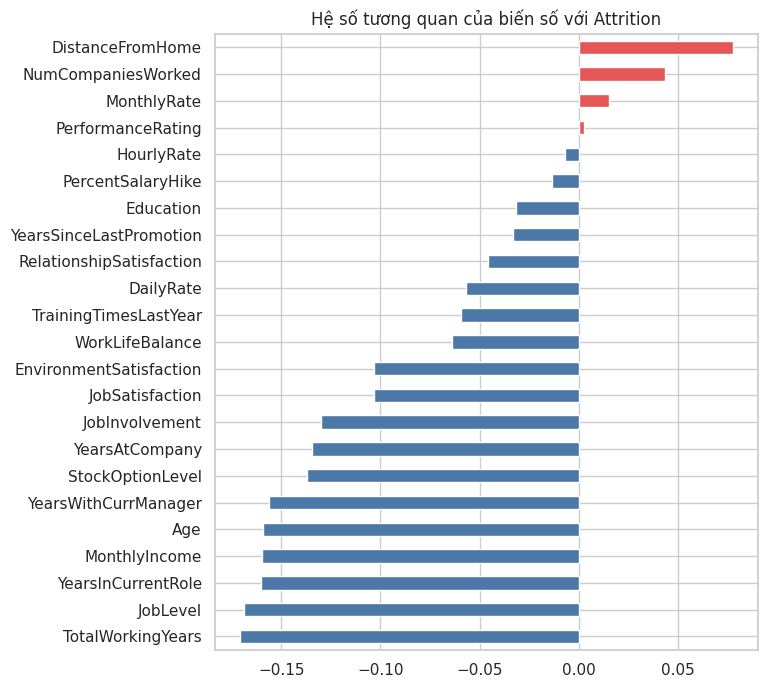

In [13]:
# Tương quan giữa các biến số với Attrition
corr = df.select_dtypes("number").corr()["Attrition"].drop("Attrition").sort_values()
corr.plot.barh(figsize=(7, 8), color=np.where(corr < 0, "#4C78A8", "#E45756"))
plt.title("Hệ số tương quan của biến số với Attrition"); plt.show()

---
## 6. Phân tích yếu tố trực tiếp và gián tiếp

- **Yếu tố trực tiếp:** Công ty **có thể thay đổi trực tiếp** bằng chính sách (làm thêm giờ, lương, cấp bậc, cổ phiếu, công tác, mức hài lòng...). Đây là nơi HR can thiệp.
- **Yếu tố gián tiếp:** Là **đặc điểm nền** của nhân viên (tuổi, hôn nhân, kinh nghiệm, khoảng cách nhà...) mà công ty không đổi được. Chúng không "gây" nghỉ việc một cách tự thân, mà có thể tác động một phần **thông qua biến trung gian** (ví dụ: tuổi trẻ → cấp bậc thấp → lương thấp → nghỉ việc). Dùng để **nhận diện nhóm rủi ro**.

In [14]:
direct = {"OverTime": "Làm thêm giờ", "MonthlyIncome": "Lương tháng", "JobLevel": "Cấp bậc",
          "StockOptionLevel": "Quyền chọn cổ phiếu", "BusinessTravel": "Mức độ công tác",
          "JobSatisfaction": "Hài lòng công việc", "EnvironmentSatisfaction": "Hài lòng môi trường",
          "WorkLifeBalance": "Cân bằng công việc - cuộc sống", "YearsSinceLastPromotion": "Thời gian chưa được thăng tiến"}
indirect = {"Age": "Tuổi", "MaritalStatus": "Tình trạng hôn nhân", "TotalWorkingYears": "Tổng số năm kinh nghiệm",
            "YearsAtCompany": "Số năm gắn bó công ty", "DistanceFromHome": "Khoảng cách nhà - công ty",
            "NumCompaniesWorked": "Số công ty đã làm", "Gender": "Giới tính"}

# Lấy p-value có sẵn từ 5.1 (Chi-square) và 5.2 (Mann-Whitney)
pv = {r["Biến"]: float(r["p_value"]) for _, r in res.iterrows()}
pv.update({r["Biến"]: float(r["p_value"]) for _, r in mw.iterrows()})
tbl = [(k, v, "Trực tiếp", pv.get(k, np.nan)) for k, v in direct.items()] + \
      [(k, v, "Gián tiếp", pv.get(k, np.nan)) for k, v in indirect.items()]
cls = pd.DataFrame(tbl, columns=["Biến", "Ý nghĩa", "Nhóm", "p_value"])
cls["Liên hệ với nghỉ việc"] = np.where(cls["p_value"] < 0.05, "Có (p<0.05)", "Không")
cls["Cách tác động"] = np.where(cls["Nhóm"] == "Trực tiếp", "HR có thể can thiệp", "Dùng nhận diện nhóm rủi ro")
cls["p_value"] = cls["p_value"].map(lambda x: f"{x:.4f}")
cls.sort_values(["Nhóm", "Biến"]).reset_index(drop=True)

,Biến,Ý nghĩa,Nhóm,p_value,Liên hệ với nghỉ việc,Cách tác động
0,Age,Tuổi,Gián tiếp,0.0000,Có (p<0.05),Dùng nhận diện nhóm rủi ro
1,DistanceFromHome,Khoảng cách nhà - công ty,Gián tiếp,0.0024,Có (p<0.05),Dùng nhận diện nhóm rủi ro
2,Gender,Giới tính,Gián tiếp,0.2906,Không,Dùng nhận diện nhóm rủi ro
3,MaritalStatus,Tình trạng hôn nhân,Gián tiếp,0.0000,Có (p<0.05),Dùng nhận diện nhóm rủi ro
4,NumCompaniesWorked,Số công ty đã làm,Gián tiếp,0.2424,Không,Dùng nhận diện nhóm rủi ro
5,TotalWorkingYears,Tổng số năm kinh nghiệm,Gián tiếp,0.0000,Có (p<0.05),Dùng nhận diện nhóm rủi ro
6,YearsAtCompany,Số năm gắn bó công ty,Gián tiếp,0.0000,Có (p<0.05),Dùng nhận diện nhóm rủi ro
7,BusinessTravel,Mức độ công tác,Trực tiếp,0.0000,Có (p<0.05),HR có thể can thiệp
8,EnvironmentSatisfaction,Hài lòng môi trường,Trực tiếp,0.0001,Có (p<0.05),HR có thể can thiệp
9,JobLevel,Cấp bậc,Trực tiếp,0.0000,Có (p<0.05),HR có thể can thiệp


**Lưu ý khi đọc bảng phân nhóm:**
- `YearsSinceLastPromotion` có $p = 0{,}0412$ ở kiểm định thô nhưng effect rất nhỏ (|effect| $\approx 0{,}08$) và **không còn ý nghĩa sau hiệu chỉnh Holm** (xem ô hiệu chỉnh ở Mục 5.2). Vì vậy chỉ coi đây là liên hệ yếu, không nên dựa vào nó để kết luận.
- `JobInvolvement` ($\chi^2 = 28{,}5$, rất có ý nghĩa ở Mục 5.1) không được đưa vào bảng này. Về bản chất đây là yếu tố **trực tiếp** (công ty tác động được qua cách giao việc), nên có thể bổ sung vào nhóm trực tiếp nếu muốn mở rộng phân tích.

### 6.1. Tương quan giữa nhóm yếu tố gián tiếp và nhóm yếu tố trực tiếp (Hiệu chỉnh Holm)

| Phân nhóm | Biến số / thứ bậc | Biến phân loại |
|---|---|---|
| **Gián tiếp** | `Age`, `TotalWorkingYears`, `YearsAtCompany`, `DistanceFromHome`, `NumCompaniesWorked` | `MaritalStatus`, `Gender` |
| **Trực tiếp** | `MonthlyIncome`, `JobLevel`, `StockOptionLevel`, `JobSatisfaction`, `EnvironmentSatisfaction`, `WorkLifeBalance`, `YearsSinceLastPromotion` | `OverTime`, `BusinessTravel` |

Vì có 4 loại cặp biến khác nhau nên dùng phép đo phù hợp cho từng loại:
- số – số: **Spearman** (có dấu, $-1$ đến $1$);
- số – phân loại: **Kruskal–Wallis**, đo bằng $\sqrt{\varepsilon^2}$ ($0$ đến $1$, không dấu);
- phân loại – phân loại: **Cramér's V** ($0$ đến $1$).

Có 63 cặp được kiểm định cùng lúc nên $p$-value được hiệu chỉnh bằng **Holm** để tránh báo "có ý nghĩa" do ngẫu nhiên.

Số cặp có ý nghĩa sau hiệu chỉnh Holm: 12 / 63


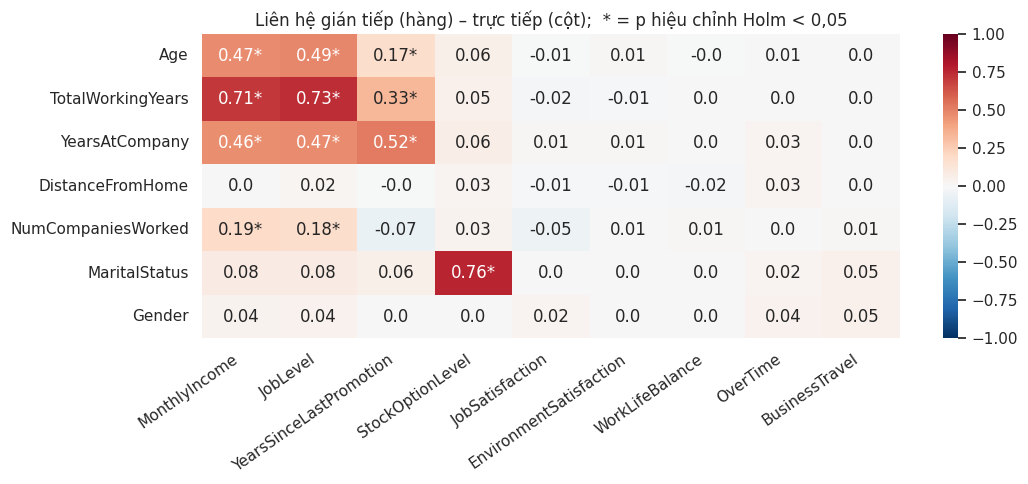

,Gián tiếp,Trực tiếp,Hệ số,p,p_Holm
47,MaritalStatus,StockOptionLevel,0.763,0.0,0.0
10,TotalWorkingYears,JobLevel,0.735,0.0,0.0
9,TotalWorkingYears,MonthlyIncome,0.710,0.0,0.0
24,YearsAtCompany,YearsSinceLastPromotion,0.520,0.0,0.0
1,Age,JobLevel,0.490,0.0,0.0
19,YearsAtCompany,JobLevel,0.472,0.0,0.0
0,Age,MonthlyIncome,0.472,0.0,0.0
18,YearsAtCompany,MonthlyIncome,0.464,0.0,0.0
15,TotalWorkingYears,YearsSinceLastPromotion,0.335,0.0,0.0
36,NumCompaniesWorked,MonthlyIncome,0.190,0.0,0.0


In [15]:
ind_num = ["Age","TotalWorkingYears","YearsAtCompany","DistanceFromHome","NumCompaniesWorked"]; ind_cat = ["MaritalStatus","Gender"]
dir_num = ["MonthlyIncome","JobLevel","StockOptionLevel","JobSatisfaction","EnvironmentSatisfaction","WorkLifeBalance","YearsSinceLastPromotion"]
dir_cat = ["OverTime","BusinessTravel"]

def cramers(a, b):
    ct = pd.crosstab(a, b); chi2 = chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum()*(min(ct.shape)-1))), chi2_contingency(ct)[1]
def num_vs_cat(x, g):
    groups = [x[g==k].values for k in g.unique()]; H, p = kruskal(*groups); n = len(x)
    return np.sqrt(max((H-len(groups)+1)/(n-len(groups)), 0)), p

rows = []
for i in ind_num + ind_cat:
    for d in dir_num + dir_cat:
        if i in ind_num and d in dir_num:   eff, p = spearmanr(df[i], df[d])
        elif i in ind_num:                  eff, p = num_vs_cat(df[i], df[d])
        elif d in dir_num:                  eff, p = num_vs_cat(df[d], df[i])
        else:                               eff, p = cramers(df[i], df[d])
        rows.append([i, d, eff, p])
assoc = pd.DataFrame(rows, columns=["Gián tiếp","Trực tiếp","Hệ số","p"])
# hiệu chỉnh Holm
m_ = len(assoc); run = 0; adj = pd.Series(index=assoc.index, dtype=float)
for rank, idx in enumerate(assoc.p.sort_values().index):
    run = max(run, min((m_-rank)*assoc.p[idx], 1)); adj[idx] = run
assoc["p_Holm"] = adj
print("Số cặp có ý nghĩa sau hiệu chỉnh Holm:", (assoc.p_Holm < 0.05).sum(), "/", len(assoc))
M = assoc.pivot(index="Gián tiếp", columns="Trực tiếp", values="Hệ số"); P = assoc.pivot(index="Gián tiếp", columns="Trực tiếp", values="p_Holm")
r_ = ind_num + ind_cat; c_ = ["MonthlyIncome","JobLevel","YearsSinceLastPromotion","StockOptionLevel","JobSatisfaction",
                            "EnvironmentSatisfaction","WorkLifeBalance","OverTime","BusinessTravel"]
M, P = M.loc[r_, c_], P.loc[r_, c_]
ann = M.round(2).astype(str).where(P >= 0.05, M.round(2).astype(str) + "*")
plt.figure(figsize=(11,5)); sns.heatmap(M, annot=ann, fmt="", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Liên hệ gián tiếp (hàng) – trực tiếp (cột);  * = p hiệu chỉnh Holm < 0,05"); plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
assoc[assoc.p_Holm < 0.05].sort_values("Hệ số", key=abs, ascending=False).round(3)

**Nhận xét ma trận tương quan Gián tiếp – Trực tiếp:**
- Chỉ **12/63 cặp** có liên hệ có ý nghĩa sau hiệu chỉnh Holm; phần còn lại gần như không liên quan.
- Liên hệ mạnh nằm ở nhóm **"thâm niên – tuổi $\leftrightarrow$ lương – cấp bậc – thăng tiến"**: `TotalWorkingYears` với `JobLevel` ($\rho \approx 0,74$) và `MonthlyIncome` ($\rho \approx 0,71$); `Age` với `JobLevel` ($\approx 0,49$) và `MonthlyIncome` ($\approx 0,47$); `YearsAtCompany` với `YearsSinceLastPromotion` ($\approx 0,52$).
- **`MaritalStatus` $\leftrightarrow$ `StockOptionLevel` rất mạnh ($\approx 0,763$)**: bảng chéo bên dưới cho thấy **toàn bộ 470 người độc thân đều có `StockOptionLevel = 0`**. Đây nhiều khả năng là **đặc điểm do cách mô phỏng dữ liệu**, không phải quy luật thật. Hệ quả: khi báo "độc thân nghỉ nhiều hơn", phần lớn là gộp lẫn với "không có cổ phiếu".
- **Không có liên hệ** giữa các yếu tố gián tiếp và nhóm *mức hài lòng, làm thêm giờ, công tác* (hệ số $\approx 0$). Nghĩa là làm thêm giờ hay mức hài lòng là các yếu tố **độc lập**, không thể suy ra từ tuổi/hôn nhân/khoảng cách.

In [16]:
pd.crosstab(df.MaritalStatus, df.StockOptionLevel, margins=True)

StockOptionLevel,0,1,2,3,All
MaritalStatus,,,,,
Divorced,8,195,75,49,327
Married,153,401,83,36,673
Single,470,0,0,0,470
All,631,596,158,85,1470


### 6.2. Kiểm tra tác động gián tiếp của Tuổi qua Cấp bậc, Lương và Kinh nghiệm
Chạy Logistic Regression hai lần – (1) chỉ có tuổi (`Age`), (2) tuổi + cấp bậc + lương + kinh nghiệm – rồi so sánh Odds Ratio (OR) của tuổi.

In [17]:
print("Tương quan Age - JobLevel         : {:.2f}".format(df["Age"].corr(df["JobLevel"])))
print("Tương quan JobLevel - MonthlyIncome: {:.2f}".format(df["JobLevel"].corr(df["MonthlyIncome"])))

def odds_ratio_age(cols):
    Z = StandardScaler().fit_transform(df[cols])
    m = LogisticRegression(penalty=None, max_iter=2000).fit(Z, df["Attrition"])
    return np.exp(m.coef_[0][0])        # odds ratio của Age (1 độ lệch chuẩn ~ 9 tuổi)

or1 = odds_ratio_age(["Age"])
or2 = odds_ratio_age(["Age", "JobLevel", "MonthlyIncome", "TotalWorkingYears"])
print(f"\nMô hình 1 (chỉ Age)                      : OR của tuổi = {or1:.2f}")
print(f"Mô hình 2 (Age + cấp bậc + lương + KN)   : OR của tuổi = {or2:.2f}")
print(f"Tác động của tuổi giảm khoảng {(1-(1-or2)/(1-or1))*100:.0f}% sau khi đưa biến trung gian vào")
print(f"Chênh lệch OR giữa hai mô hình              : {or2-or1:+.2f}")

Tương quan Age - JobLevel         : 0.51
Tương quan JobLevel - MonthlyIncome: 0.95

Mô hình 1 (chỉ Age)                      : OR của tuổi = 0.62
Mô hình 2 (Age + cấp bậc + lương + KN)   : OR của tuổi = 0.81
Tác động của tuổi giảm khoảng 49% sau khi đưa biến trung gian vào
Chênh lệch OR giữa hai mô hình              : +0.19


**Cách đọc và Lưu ý:** OR (odds ratio) $< 1$ nghĩa là tuổi càng cao thì nguy cơ nghỉ càng thấp. OR tiến từ `0.62` lên `0.81` ở mô hình 2 (giảm khoảng 49% độ lệch so với 1) khi kiểm soát cấp bậc, lương và kinh nghiệm (`TotalWorkingYears`). Ở **Mục 12**, chúng ta sẽ kiểm tra chi tiết hơn khi chỉ kiểm soát thuần túy các biến **trực tiếp** (không gộp `TotalWorkingYears`).

---
## 7. Xây dựng mô hình cơ sở (Baseline Models)
Dùng 3 mô hình cơ sở quen thuộc: **Logistic Regression**, **Decision Tree**, **Random Forest** kết hợp với `make_pipe` đã thiết lập ở Mục 3. Để xử lý mất cân bằng lớp, đặt `class_weight="balanced"`.

In [18]:
pipes = {
    "Logistic Regression": make_pipe(LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Decision Tree":       make_pipe(DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)),
    "Random Forest":       make_pipe(RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42)),
}
results, preds = [], {}
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    pred, prob = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    preds[name] = pred
    results.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                    recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)])
res_df = pd.DataFrame(results, columns=["Mô hình", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).set_index("Mô hình").round(3)
res_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Mô hình,,,,,
Logistic Regression,0.755,0.356,0.660,0.463,0.804
Decision Tree,0.728,0.301,0.532,0.385,0.686
Random Forest,0.827,0.400,0.170,0.239,0.781


---
## 8. Đánh giá mô hình cơ sở (Confusion Matrix & Stratified Cross-Validation)
**Cách đọc:** *Recall* = trong số người thực sự nghỉ việc, mô hình bắt được bao nhiêu %. Với bài toán nhân sự, Recall quan trọng vì bỏ sót người sắp nghỉ tốn kém hơn cảnh báo nhầm.

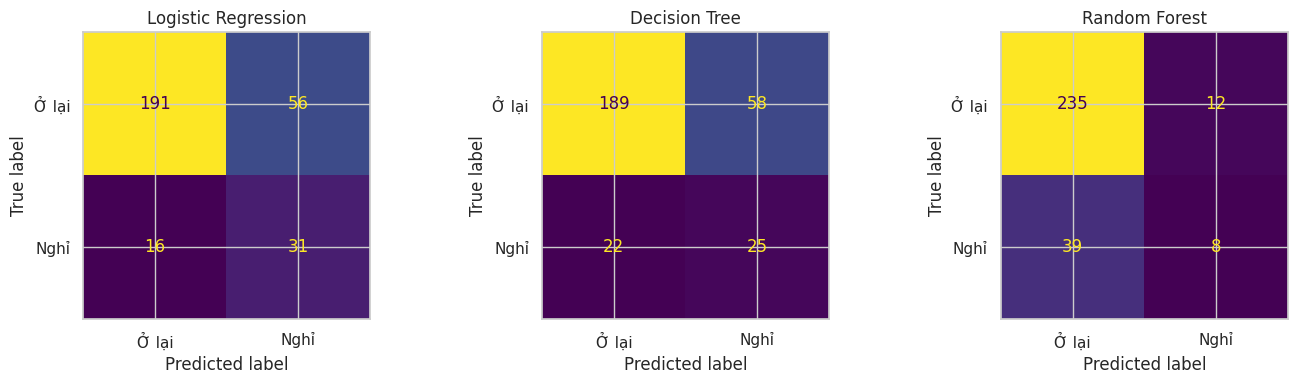

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Ở lại", "Nghỉ"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 8.1. Stratified 5-Fold Cross-Validation (Kiểm tra độ ổn định trên tập Train)
Tập test chỉ có 47 người nghỉ việc nên các chỉ số trên có thể dao động tùy cách chia. Dùng **Stratified 5-fold cross-validation** trên tập train để lấy trung bình $\pm$ độ lệch chuẩn.

In [20]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, pipe in pipes.items():
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=["recall", "precision", "f1", "roc_auc"])
    rows.append([name] + [f"{cv['test_'+m].mean():.3f} ± {cv['test_'+m].std():.3f}" for m in ["recall", "precision", "f1", "roc_auc"]])
cv_df = pd.DataFrame(rows, columns=["Mô hình", "Recall", "Precision", "F1", "ROC-AUC"]).set_index("Mô hình")
cv_df

,Recall,Precision,F1,ROC-AUC
Mô hình,,,,
Logistic Regression,0.732 ± 0.065,0.362 ± 0.032,0.483 ± 0.033,0.827 ± 0.028
Decision Tree,0.558 ± 0.102,0.335 ± 0.044,0.414 ± 0.043,0.686 ± 0.030
Random Forest,0.242 ± 0.077,0.737 ± 0.138,0.359 ± 0.097,0.789 ± 0.034


**Nhận xét:** Thứ hạng các mô hình trong 5-fold CV hoàn toàn nhất quán với tập Test: **Logistic Regression** đạt ROC-AUC cao nhất (`0.827 ± 0.028`) và Recall cao nhất (`0.732 ± 0.065`) với độ lệch chuẩn nhỏ nhất.

---
## 9. Phân tích yếu tố quan trọng (Feature Importance, Hệ số Logistic Regression & Cây quyết định)

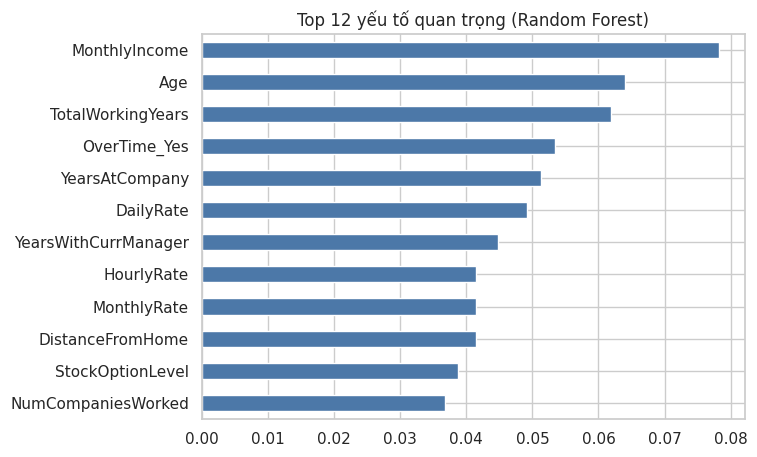

In [21]:
rf = pipes["Random Forest"].named_steps["model"]
cols_after = continuous_cols + [c for c in X.columns if c not in continuous_cols]   # thứ tự cột sau ColumnTransformer
imp = pd.Series(rf.feature_importances_, index=cols_after).sort_values().tail(12)
imp.plot.barh(figsize=(7, 5), color="#4C78A8")
plt.title("Top 12 yếu tố quan trọng (Random Forest)"); plt.show()

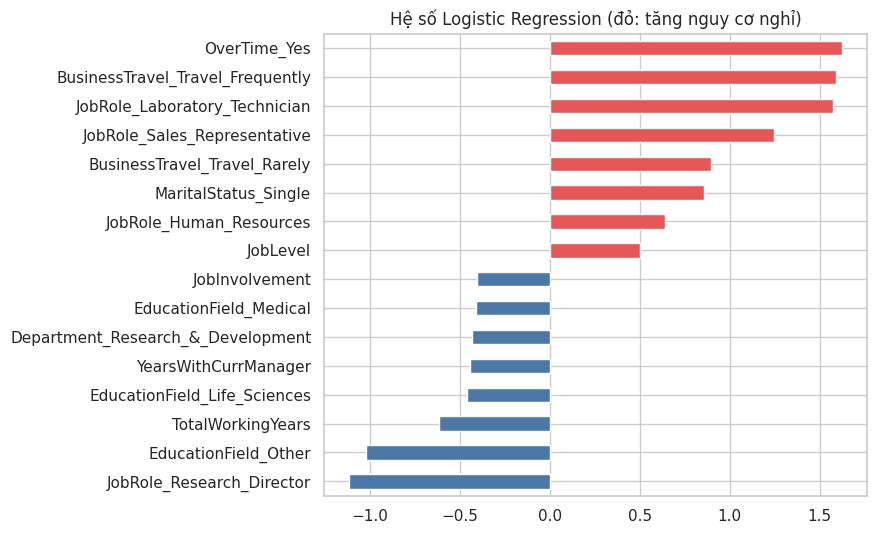

In [22]:
# Hệ số Logistic Regression (đã scale cột liên tục): dương = tăng nguy cơ nghỉ, âm = giảm nguy cơ
lr = pipes["Logistic Regression"].named_steps["model"]
coef = pd.Series(lr.coef_[0], index=cols_after).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
top.plot.barh(figsize=(7, 6), color=np.where(top < 0, "#4C78A8", "#E45756"))
plt.title("Hệ số Logistic Regression (đỏ: tăng nguy cơ nghỉ)"); plt.show()

Lưu ý: `JobLevel` và `MonthlyIncome` tương quan rất cao với nhau ($0,95$ — đa cộng tuyến) nên dấu hệ số của từng biến riêng lẻ có thể bù trừ nhau; nên đọc chúng cùng nhau.

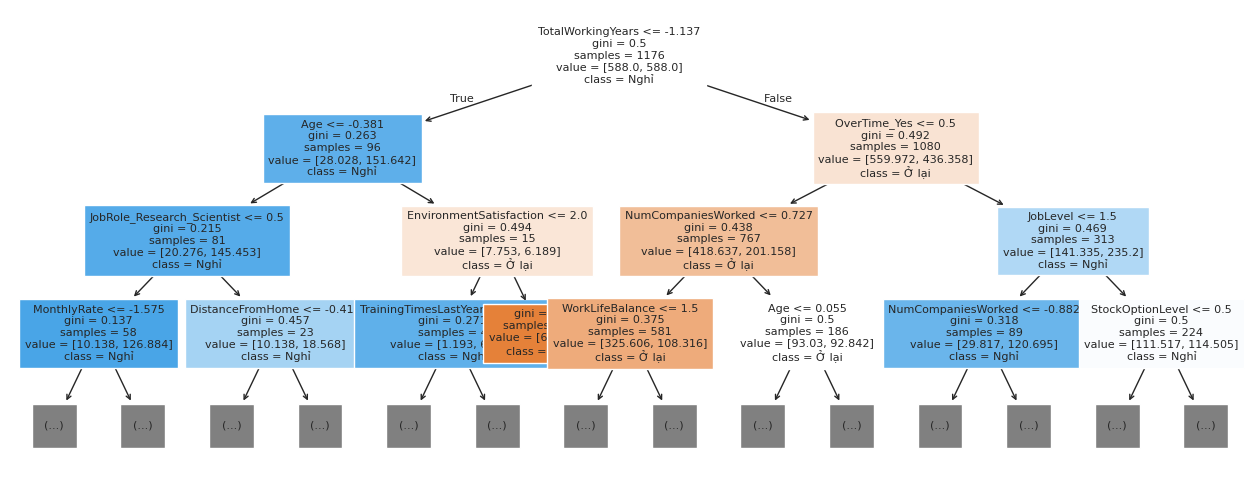

In [23]:
# Cây quyết định nông - dễ giải thích bằng lời
plt.figure(figsize=(16, 6))
plot_tree(pipes["Decision Tree"].named_steps["model"], feature_names=cols_after, class_names=["Ở lại", "Nghỉ"],
          filled=True, fontsize=8, max_depth=3)
plt.show()

---
## 10. Mô hình nâng cao (XGBoost, LightGBM) và Tối ưu siêu tham số (Tuning)
**Mô hình thêm vào:** XGBoost và LightGBM (gradient boosting trên cây). Cả hai xử lý mất cân bằng bằng `scale_pos_weight` / `class_weight`.

**Cách tuning:** `RandomizedSearchCV` (thử ngẫu nhiên 20–25 tổ hợp) với Stratified 5-fold **chỉ trên tập train**, tối ưu theo **ROC-AUC**. Chọn ROC-AUC vì không phụ thuộc ngưỡng 0,5; ngưỡng cảnh báo sẽ chọn riêng ở mục ứng dụng.

In [24]:
spw = (y_train==0).sum() / (y_train==1).sum()
spaces = {
 "Logistic Regression": (make_pipe(LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000)),
     {"model__C": loguniform(1e-3, 1e2), "model__penalty": ["l1","l2"]}, 25),
 "Random Forest": (make_pipe(RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=1)),
     {"model__n_estimators": randint(100,400), "model__max_depth": randint(3,12),
      "model__min_samples_leaf": randint(1,15), "model__max_features": ["sqrt","log2",0.3]}, 20),
 "XGBoost": (make_pipe(XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42, n_jobs=1, verbosity=0)),
     {"model__n_estimators": randint(100,400), "model__max_depth": randint(2,6), "model__learning_rate": loguniform(0.01,0.2),
      "model__subsample": uniform(0.6,0.4), "model__colsample_bytree": uniform(0.5,0.5),
      "model__min_child_weight": randint(1,10), "model__reg_lambda": loguniform(0.1,20)}, 25),
 "LightGBM": (make_pipe(LGBMClassifier(class_weight="balanced", random_state=42, n_jobs=1, verbose=-1)),
     {"model__n_estimators": randint(100,400), "model__max_depth": randint(2,6), "model__learning_rate": loguniform(0.01,0.2),
      "model__num_leaves": randint(4,24), "model__subsample": uniform(0.6,0.4), "model__subsample_freq": [1],
      "model__colsample_bytree": uniform(0.5,0.5), "model__min_child_samples": randint(10,50),
      "model__reg_lambda": loguniform(0.1,20)}, 25),
}
skf = StratifiedKFold(5, shuffle=True, random_state=42)
rows, searches = [], {}
for name,(pipe,space,n) in spaces.items():
    rs = RandomizedSearchCV(pipe, space, n_iter=n, scoring="roc_auc", cv=skf, random_state=42, n_jobs=1).fit(X_train, y_train)
    searches[name] = rs
    pred, prob = rs.predict(X_test), rs.predict_proba(X_test)[:,1]
    rows.append([name, rs.best_score_, precision_score(y_test,pred), recall_score(y_test,pred), f1_score(y_test,pred), roc_auc_score(y_test,prob)])
tuned = pd.DataFrame(rows, columns=["Mô hình","CV AUC (lúc tuning)","Precision@0.5","Recall@0.5","F1@0.5","ROC-AUC test"]).set_index("Mô hình").round(3)
tuned

,CV AUC (lúc tuning),Precision@0.5,Recall@0.5,F1@0.5,ROC-AUC test
Mô hình,,,,,
Logistic Regression,0.832,0.364,0.681,0.474,0.803
Random Forest,0.806,0.429,0.128,0.197,0.800
XGBoost,0.825,0.410,0.681,0.512,0.802
LightGBM,0.828,0.403,0.532,0.459,0.798


**Lưu ý khi đọc bảng:** cột Precision/Recall/F1 dùng ngưỡng cố định 0,5 nên **không công bằng** với mô hình cho xác suất dốc (ví dụ Random Forest sau tuning có thể có Recall rất thấp ở ngưỡng 0,5 dù AUC vẫn tốt). So sánh mô hình nên dựa vào chỉ số không phụ thuộc ngưỡng (ROC-AUC, PR-AUC) hoặc tỷ lệ bắt được ở top 20% như bên dưới. Điểm CV lúc tuning cũng hơi **lạc quan** vì chính các fold đó đã được dùng để chọn tham số.

In [25]:
for name, rs in searches.items():
    print(name, {k.replace("model__",""): (round(v,3) if isinstance(v,float) else v) for k,v in rs.best_params_.items()})

Logistic Regression {'C': np.float64(0.179), 'penalty': 'l2'}
Random Forest {'max_depth': 11, 'max_features': 0.3, 'min_samples_leaf': 2, 'n_estimators': 188}
XGBoost {'colsample_bytree': np.float64(0.55), 'learning_rate': np.float64(0.04), 'max_depth': 2, 'min_child_weight': 4, 'n_estimators': 251, 'reg_lambda': np.float64(3.146), 'subsample': np.float64(0.623)}
LightGBM {'colsample_bytree': np.float64(0.971), 'learning_rate': np.float64(0.06), 'max_depth': 4, 'min_child_samples': 31, 'n_estimators': 383, 'num_leaves': 5, 'reg_lambda': np.float64(2.733), 'subsample': np.float64(0.718), 'subsample_freq': 1}


---
## 11. So sánh mô hình công bằng bằng Nested Cross-Validation
Vòng ngoài (5 fold) chỉ để **đo**, vòng trong (3 fold) chỉ để **tuning** $\rightarrow$ điểm số không bị lạc quan. So sánh mô hình mặc định với mô hình đã tuning. Dùng toàn bộ 1.470 dòng để có nhiều ca nghỉ việc hơn cho mỗi lần đo. *Lưu ý cấu hình:* để giảm thời gian chạy, vòng trong dùng 3-fold và `n_iter = max(10, k//2)` (10–12 tổ hợp), ít hơn 20–25 tổ hợp ở Mục 10 nên kết quả tuning ở đây có thể kém tối ưu hơn một chút.
- **PR-AUC**: phù hợp với dữ liệu mất cân bằng (mốc ngẫu nhiên $\approx$ tỷ lệ nghỉ việc 0,16).
- **Bắt được ở top 20%**: nếu HR chỉ xử lý 20% nhân viên có điểm cao nhất thì bắt được bao nhiêu % người nghỉ (ngẫu nhiên $\approx 20\%$).

In [26]:
Xa, ya = X.reset_index(drop=True), y.reset_index(drop=True)
outer = StratifiedKFold(5, shuffle=True, random_state=7)
inner = StratifiedKFold(3, shuffle=True, random_state=42)
spw_all = (ya==0).sum() / (ya==1).sum()
defaults = {
 "Logistic Regression (mặc định)": make_pipe(LogisticRegression(class_weight="balanced", max_iter=1000)),
 "Random Forest (mặc định)":       make_pipe(RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42)),
 "XGBoost (mặc định)":             make_pipe(XGBClassifier(scale_pos_weight=spw_all, eval_metric="logloss", random_state=42, n_jobs=1, verbosity=0)),
 "LightGBM (mặc định)":            make_pipe(LGBMClassifier(class_weight="balanced", random_state=42, n_jobs=1, verbose=-1)),
}
def top20(yt, pr):
    k = int(len(yt)*0.2); return yt.iloc[np.argsort(-pr)[:k]].sum() / yt.sum()
def evaluate(make_est):
    oof, aucs = np.zeros(len(ya)), []
    for tr, te in outer.split(Xa, ya):
        est = make_est().fit(Xa.iloc[tr], ya.iloc[tr]); p = est.predict_proba(Xa.iloc[te])[:,1]
        oof[te] = p; aucs.append(roc_auc_score(ya.iloc[te], p))
    return [np.mean(aucs), np.std(aucs), average_precision_score(ya, oof), top20(ya, oof)]
nested_res = {n: evaluate(lambda p=p: clone(p)) for n,p in defaults.items()}
for n,(pipe,space,k) in spaces.items():
    nested_res[n+" (tuning)"] = evaluate(lambda pipe=pipe,space=space,k=k: RandomizedSearchCV(
        clone(pipe), space, n_iter=max(10,k//2), scoring="roc_auc", cv=inner, random_state=42, n_jobs=1))
nested = pd.DataFrame(nested_res, index=["ROC-AUC (TB)","ROC-AUC (SD)","PR-AUC","Bắt được ở top 20%"]).T.round(3)
nested

,ROC-AUC (TB),ROC-AUC (SD),PR-AUC,Bắt được ở top 20%
Logistic Regression (mặc định),0.826,0.036,0.585,0.595
Random Forest (mặc định),0.796,0.038,0.508,0.565
XGBoost (mặc định),0.798,0.021,0.520,0.549
LightGBM (mặc định),0.804,0.021,0.532,0.561
Logistic Regression (tuning),0.818,0.041,0.561,0.586
Random Forest (tuning),0.806,0.032,0.524,0.570
XGBoost (tuning),0.821,0.045,0.595,0.603
LightGBM (tuning),0.823,0.030,0.593,0.603


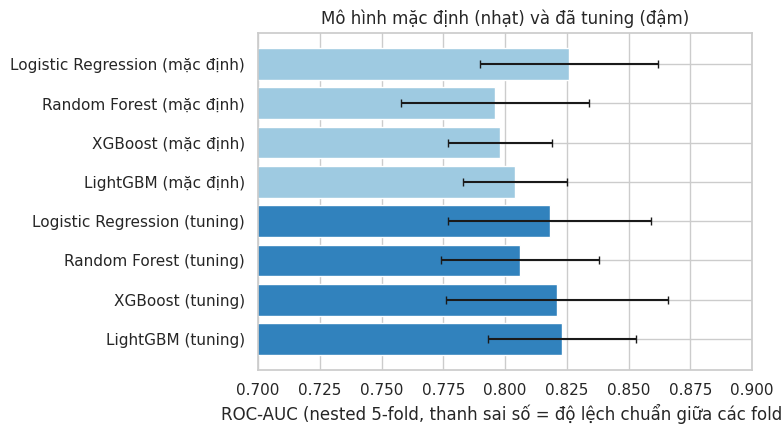

In [27]:
fig, ax = plt.subplots(figsize=(8,4.5))
m = nested["ROC-AUC (TB)"]; s = nested["ROC-AUC (SD)"]
colors = ["#9ecae1" if "mặc định" in i else "#3182bd" for i in m.index]
ax.barh(m.index[::-1], m.values[::-1], xerr=s.values[::-1], color=colors[::-1], capsize=3)
ax.set_xlim(0.7, 0.9); ax.set_xlabel("ROC-AUC (nested 5-fold, thanh sai số = độ lệch chuẩn giữa các fold)")
ax.set_title("Mô hình mặc định (nhạt) và đã tuning (đậm)"); plt.tight_layout(); plt.show()

**Nhận xét (đọc cùng bảng trên):**
- Tuning **cải thiện rõ cho XGBoost và LightGBM** (ROC-AUC tăng khoảng 0,02 và PR-AUC tăng từ $\approx 0,52 - 0,53$ lên $\approx 0,59$), đưa chúng lên ngang Logistic Regression.
- **Logistic Regression không hưởng lợi từ tuning** (mặc định đã gần tối ưu; điểm sau tuning thậm chí thấp hơn chút, do nhiễu).
- Chênh lệch giữa các mô hình tốt nhất ($\approx 0,82$) **nhỏ hơn độ lệch chuẩn giữa các fold ($\approx 0,03 - 0,04$)**, nên không thể khẳng định mô hình nào vượt trội. Với dữ liệu này, mô hình phức tạp hơn **không** cho kết quả tốt hơn rõ rệt; Logistic Regression vẫn là lựa chọn hợp lý nhờ đơn giản và dễ giải thích.
- Trần $\approx 0,82$ **có thể** phần lớn do chính dữ liệu (mô phỏng, chỉ 237 ca nghỉ) hơn là do thiếu tuning; đây là nhận định chưa được kiểm chứng riêng.

---
## 12. Phân tích bổ sung yếu tố trực tiếp và gián tiếp
Tương quan cao giữa hai biến chưa đủ để kết luận có hiệu ứng trung gian. Hai kiểm tra đơn giản:
1. **Khả năng dự đoán:** so sánh ROC-AUC (5-fold CV, Logistic Regression) của mô hình chỉ dùng biến gián tiếp, chỉ dùng biến trực tiếp, và dùng cả hai.
2. **Odds ratio của từng biến gián tiếp** trước và sau khi thêm toàn bộ biến trực tiếp. Nếu OR tiến về 1 rõ rệt thì tác động của biến đó phần lớn đi qua biến trực tiếp.

In [28]:
def design(num, cats): return pd.get_dummies(df[num+cats], columns=cats, drop_first=True).astype(float)
Xi = design(ind_num, ind_cat); Xd = design(dir_num, dir_cat); Xb = pd.concat([Xi, Xd], axis=1)
def cv_auc(Xm):
    s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)), Xm, y, cv=skf, scoring="roc_auc")
    return f"{s.mean():.3f} ± {s.std():.3f}"
print(pd.DataFrame({"Số biến":[Xi.shape[1], Xd.shape[1], Xb.shape[1]],
                    "ROC-AUC (CV)":[cv_auc(Xi), cv_auc(Xd), cv_auc(Xb)]}, index=["Chỉ gián tiếp","Chỉ trực tiếp","Cả hai"]))

def coef(Xm):
    Z = StandardScaler().fit_transform(Xm); return pd.Series(LogisticRegression(penalty=None, max_iter=5000).fit(Z, y).coef_[0], index=Xm.columns)
rows = []
for v in ind_num:                                    # từng biến gián tiếp riêng lẻ
    a = coef(df[[v]].astype(float)).iloc[0]; b = coef(pd.concat([df[[v]].astype(float), Xd], axis=1))[v]
    rows.append([v, np.exp(a), np.exp(b), (1 - b/a)*100])
med = pd.DataFrame(rows, columns=["Biến gián tiếp","OR (chỉ biến này)","OR (thêm toàn bộ trực tiếp)","% tác động đi qua trực tiếp"]).set_index("Biến gián tiếp").round(2)
med

               Số biến   ROC-AUC (CV)
Chỉ gián tiếp        8  0.701 ± 0.036
Chỉ trực tiếp       10  0.780 ± 0.024
Cả hai              18  0.806 ± 0.027


,OR (chỉ biến này),OR (thêm toàn bộ trực tiếp),% tác động đi qua trực tiếp
Biến gián tiếp,,,
Age,0.62,0.71,29.22
TotalWorkingYears,0.55,0.54,-2.07
YearsAtCompany,0.61,0.58,-8.77
DistanceFromHome,1.22,1.32,-37.64
NumCompaniesWorked,1.12,1.29,-123.80


**Nhận xét:**
- Biến trực tiếp dự đoán tốt hơn hẳn biến gián tiếp ($\approx 0,78$ so với $\approx 0,70$); gộp cả hai chỉ nâng lên $\approx 0,81$. Biến gián tiếp **bổ sung thêm một chút** thông tin chứ không bị biến trực tiếp thay thế hoàn toàn.
- Với các biến gián tiếp, tác động **không bị "hấp thụ" hoàn toàn bởi biến trực tiếp** như giả thuyết: OR của `Age` chỉ tiến từ `0.62` lên `0.71` (khoảng 29% tác động đi qua biến trực tiếp), còn `TotalWorkingYears` và `YearsAtCompany` gần như không đổi; `DistanceFromHome` và `NumCompaniesWorked` thậm chí **mạnh hơn** sau khi kiểm soát (giá trị âm = hiện tượng *suppression*, không phải lỗi).
- **Đối chiếu với Mục 6.2:** con số "giảm khoảng 49%" (`0.62` $\rightarrow$ `0.81`) ở Mục 6.2 có đưa `TotalWorkingYears` (là biến gián tiếp) vào làm biến trung gian. Khi chỉ dùng các biến **trực tiếp** làm trung gian, mức giảm là khoảng 29%. Do đó nên hiểu rằng tác động của tuổi đi qua yếu tố trung gian **một phần (khoảng 29–49% tùy cách chọn biến kiểm soát)**.
- Đây vẫn chỉ là phân tích liên hệ, chưa phải mô hình trung gian đầy đủ và không chứng minh nhân quả.

### 12.1. Tác động của từng yếu tố trực tiếp (odds ratio)
Trả lời câu hỏi “yếu tố trực tiếp tác động đến nghỉ việc như thế nào”. Với mỗi yếu tố, tính **odds ratio (OR)** bằng hồi quy Logistic: OR > 1 nghĩa là tăng yếu tố đó thì odds nghỉ việc tăng; OR < 1 nghĩa là giảm. Có hai cách: **đơn biến** (từng yếu tố riêng lẻ) và **đa biến** (đưa tất cả yếu tố trực tiếp vào cùng lúc, tức tác động của một yếu tố khi giữ các yếu tố khác không đổi). Khoảng tin cậy 95% (CI) không chứa 1 thì có ý nghĩa.

In [29]:
# Odds ratio của từng yếu tố trực tiếp: đơn biến (từng yếu tố riêng lẻ) và đa biến (đưa tất cả vào cùng lúc)
import statsmodels.api as sm   # (Colab đã có sẵn statsmodels)

# Chuẩn bị biến trực tiếp với đơn vị dễ đọc
D = pd.DataFrame({
    "OverTime (Có so với Không)": (df["OverTime"] == "Yes").astype(float),
    "BusinessTravel: Thường xuyên (so với Không đi)": (df["BusinessTravel"] == "Travel_Frequently").astype(float),
    "BusinessTravel: Hiếm khi (so với Không đi)": (df["BusinessTravel"] == "Travel_Rarely").astype(float),
    "MonthlyIncome (mỗi +1.000)": df["MonthlyIncome"] / 1000,
    "JobLevel (mỗi +1 bậc)": df["JobLevel"].astype(float),
    "StockOptionLevel (mỗi +1 mức)": df["StockOptionLevel"].astype(float),
    "JobSatisfaction (mỗi +1 điểm)": df["JobSatisfaction"].astype(float),
    "EnvironmentSatisfaction (mỗi +1 điểm)": df["EnvironmentSatisfaction"].astype(float),
    "WorkLifeBalance (mỗi +1 điểm)": df["WorkLifeBalance"].astype(float),
    "YearsSinceLastPromotion (mỗi +1 năm)": df["YearsSinceLastPromotion"].astype(float),
})
y = df["Attrition"]

def or_table(cols):
    m = sm.Logit(y, sm.add_constant(D[cols])).fit(disp=0)
    ci = np.exp(m.conf_int()); ci.columns = ["lo", "hi"]
    t = pd.DataFrame({"OR": np.exp(m.params), "CI 95%": ci.round(2).astype(str).agg(" – ".join, axis=1), "p": m.pvalues}).drop("const")
    return t

# (a) từng yếu tố riêng lẻ (đơn biến)
rows = []
for c in D.columns:
    if "Hiếm" in c or "Thường" in c:
        continue
    t = or_table([c]); rows.append((c, t.iloc[0]["OR"], t.iloc[0]["CI 95%"], t.iloc[0]["p"]))
bt = or_table([c for c in D.columns if "BusinessTravel" in c])        # công tác: 2 biến giả đi cùng nhau
for c in bt.index: rows.append((c, bt.loc[c, "OR"], bt.loc[c, "CI 95%"], bt.loc[c, "p"]))
uni = pd.DataFrame(rows, columns=["Yếu tố trực tiếp", "OR đơn biến", "CI 95%", "p"]).set_index("Yếu tố trực tiếp")

# (b) đa biến: đưa tất cả yếu tố trực tiếp vào cùng lúc
multi = or_table(list(D.columns))
res = uni.join(multi.rename(columns={"OR": "OR đa biến", "CI 95%": "CI 95% (đa biến)", "p": "p (đa biến)"}))
res["OR đơn biến"] = res["OR đơn biến"].round(2); res["OR đa biến"] = res["OR đa biến"].round(2)
res["p"] = res["p"].map(lambda v: f"{v:.4f}"); res["p (đa biến)"] = res["p (đa biến)"].map(lambda v: f"{v:.4f}")
print(res.to_string())
print("Tương quan JobLevel - MonthlyIncome:", round(df["JobLevel"].corr(df["MonthlyIncome"]), 2))


                                                OR đơn biến       CI 95%       p  OR đa biến CI 95% (đa biến) p (đa biến)
Yếu tố trực tiếp                                                                                                         
OverTime (Có so với Không)                             3.77  2.83 – 5.03  0.0000        4.68      3.41 – 6.43      0.0000
MonthlyIncome (mỗi +1.000)                             0.88  0.84 – 0.92  0.0000        0.93      0.83 – 1.05      0.2551
JobLevel (mỗi +1 bậc)                                  0.59   0.5 – 0.69  0.0000        0.69       0.44 – 1.1      0.1178
StockOptionLevel (mỗi +1 mức)                          0.60  0.49 – 0.72  0.0000        0.59      0.48 – 0.72      0.0000
JobSatisfaction (mỗi +1 điểm)                          0.78  0.69 – 0.88  0.0001        0.72      0.63 – 0.83      0.0000
EnvironmentSatisfaction (mỗi +1 điểm)                  0.78  0.68 – 0.88  0.0001        0.70      0.61 – 0.81      0.0000
WorkLifeBalance (mỗi +1 

**Nhận xét:**
- **Làm thêm giờ** là yếu tố trực tiếp mạnh nhất: odds nghỉ việc cao gấp khoảng **3,8 lần** (đơn biến) và **4,7 lần** (đa biến) so với không làm thêm.
- **Công tác thường xuyên** (so với không đi công tác) nhân odds lên khoảng **3,7–3,8 lần**; công tác hiếm khi cũng cao hơn (đơn biến 2,0).
- Mỗi mức **cổ phiếu**, mỗi điểm **hài lòng công việc**, **hài lòng môi trường** và **cân bằng công việc – cuộc sống** đều làm **giảm** odds nghỉ (OR khoảng 0,6–0,8) và vẫn có ý nghĩa ở mô hình đa biến.
- **Lương và cấp bậc** có ý nghĩa ở đơn biến (mỗi +1.000 lương: OR 0,88; mỗi bậc: OR 0,59) nhưng **mất ý nghĩa ở đa biến** vì `JobLevel` và `MonthlyIncome` tương quan 0,95: hai biến “chia nhau” cùng một thông tin. Vì vậy nên đọc chung thành *nhóm lương – cấp bậc*, không nên diễn giải từng biến riêng.
- **Thời gian chưa được thăng tiến** không có ý nghĩa ở cả hai mô hình (OR ≈ 1), khớp với kết quả Holm ở Mục 5.2.
- Đây vẫn là liên hệ thống kê, không chứng minh nhân quả.

---
## 13. Ứng dụng thực tế cho bộ phận nhân sự (HR)
Dùng **Logistic Regression** (đủ tốt, ổn định và dễ giải thích; điểm số ngang các mô hình boosting đã tuning ở Mục 11) để chấm điểm rủi ro nghỉ việc cho từng nhân viên.

### 13.1. Chọn ngưỡng cảnh báo
Ngưỡng càng cao $\rightarrow$ danh sách càng ngắn và chính xác hơn (Precision tăng) nhưng bỏ sót nhiều hơn (Recall giảm). Bảng dưới giúp HR cân nhắc theo nguồn lực.

In [30]:
best = pipes["Logistic Regression"]
prob_test = best.predict_proba(X_test)[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    flag = prob_test >= t
    tp = (flag & (y_test == 1)).sum()
    rows.append([t, int(flag.sum()), f"{flag.mean():.0%}", round(tp / max(flag.sum(), 1), 2), round(tp / (y_test == 1).sum(), 2)])
thr = pd.DataFrame(rows, columns=["Ngưỡng", "Số người bị cảnh báo", "% nhân viên", "Precision", "Recall"]).set_index("Ngưỡng")
thr

,Số người bị cảnh báo,% nhân viên,Precision,Recall
Ngưỡng,,,,
0.3,134,46%,0.28,0.81
0.4,108,37%,0.35,0.81
0.5,87,30%,0.36,0.66
0.6,59,20%,0.46,0.57
0.7,41,14%,0.51,0.45


**Đề xuất sử dụng (ngưỡng 0,6 là ngưỡng cảnh báo mặc định):**
- **Xác suất $\ge 0,6$ (rủi ro cao):** HR phỏng vấn giữ chân, rà soát lương – cấp bậc – lộ trình thăng tiến, xem lại khối lượng làm thêm giờ.
- **$0,4 - 0,6$ (theo dõi):** khảo sát mức hài lòng, trao đổi với quản lý trực tiếp.
- **$< 0,4$ (ổn định):** không cần can thiệp riêng.
Điểm số chỉ để **xếp thứ tự ưu tiên**, không phải kết luận chắc chắn về từng người (Precision còn thấp).

*Lưu ý:* bảng ngưỡng ở 13.1 tính trên tập test nên ngưỡng 0,6 hơi lạc quan; xem kiểm tra out-of-fold ở 13.1b bên dưới.


**Kiểm tra độc lập (13.1b):** bảng ngưỡng ở trên được tính trên chính tập test, nên việc chọn ngưỡng 0,6 hơi lạc quan. Ô dưới đây tính lại bảng ngưỡng bằng dự đoán *out-of-fold* trên tập train (5-fold), tức không dùng tập test để chọn ngưỡng. Nếu kết quả gần với bảng trên thì ngưỡng 0,6 đáng tin hơn.

In [31]:
from sklearn.model_selection import cross_val_predict
oof_prob = cross_val_predict(make_pipe(LogisticRegression(class_weight="balanced", max_iter=1000)),
                             X_train, y_train, cv=skf, method="predict_proba")[:, 1]
yt = y_train.values
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    flag = oof_prob >= t
    tp = (flag & (yt == 1)).sum()
    rows.append([t, int(flag.sum()), f"{flag.mean():.0%}", round(tp / max(flag.sum(), 1), 2), round(tp / (yt == 1).sum(), 2)])
pd.DataFrame(rows, columns=["Ngưỡng", "Số người bị cảnh báo", "% nhân viên", "Precision", "Recall"]).set_index("Ngưỡng")

,Số người bị cảnh báo,% nhân viên,Precision,Recall
Ngưỡng,,,,
0.3,571,49%,0.29,0.86
0.4,469,40%,0.32,0.79
0.5,386,33%,0.36,0.73
0.6,279,24%,0.46,0.67
0.7,200,17%,0.56,0.59


**Nhận xét 13.1b:** tính bằng dự đoán out-of-fold trên tập train (không dùng tập test), ở ngưỡng 0,6 mô hình gắn cờ khoảng **24%** nhân viên với **Precision 0,46** (bằng với bảng trên tập test) và **Recall 0,67** (tập test là 0,57). Kết quả nhất quán nên ngưỡng 0,6 **không** bị lạc quan: Precision giữ nguyên, Recall thậm chí cao hơn. Ngưỡng 0,7 cho Precision cao hơn (0,56) nhưng Recall giảm còn 0,59. (Các số này có thể lệch rất nhỏ giữa các lần chạy / phiên bản thư viện.)

In [32]:
risk = X_test.copy()
risk["Xác suất nghỉ"] = prob_test.round(2)
risk["Mức rủi ro"] = pd.cut(prob_test, [0, 0.4, 0.6, 1.01], labels=["Ổn định", "Theo dõi", "Cao"], right=False)
risk["Thực tế"] = y_test.map({0: "Ở lại", 1: "Nghỉ"})
print(risk["Mức rủi ro"].value_counts().to_string())
risk[["Age", "MonthlyIncome", "OverTime_Yes", "YearsAtCompany", "Xác suất nghỉ", "Mức rủi ro", "Thực tế"]] \
    .sort_values("Xác suất nghỉ", ascending=False).head(10)

Mức rủi ro
Ổn định     186
Cao          59
Theo dõi     49


,Age,MonthlyIncome,OverTime_Yes,YearsAtCompany,Xác suất nghỉ,Mức rủi ro,Thực tế
357,21,2174,True,3,0.99,Cao,Nghỉ
911,25,1118,True,1,0.99,Cao,Nghỉ
688,19,2121,True,1,0.97,Cao,Nghỉ
946,40,9094,True,5,0.96,Cao,Nghỉ
1021,25,4400,False,3,0.96,Cao,Nghỉ
762,26,2042,True,3,0.95,Cao,Nghỉ
132,31,4559,True,2,0.94,Cao,Nghỉ
514,33,3348,True,10,0.93,Cao,Nghỉ
525,24,4577,False,2,0.92,Cao,Nghỉ
829,33,8224,True,5,0.91,Cao,Nghỉ


In [33]:
# 20% nhân viên có điểm rủi ro cao nhất chứa bao nhiêu % người thực sự nghỉ?
r = risk.sort_values("Xác suất nghỉ", ascending=False)
k = int(len(r) * 0.2)
cap = (r["Thực tế"].head(k) == "Nghỉ").sum() / (y_test == 1).sum()
print(f"20% nhân viên rủi ro cao nhất (theo Logistic Regression) bắt được {cap:.0%} số người nghỉ việc (ngẫu nhiên chỉ ~20%)")

20% nhân viên rủi ro cao nhất (theo Logistic Regression) bắt được 55% số người nghỉ việc (ngẫu nhiên chỉ ~20%)


### 13.2. Hàm chấm điểm cho nhân viên mới (`score_employee`)
Nhập thông tin một nhân viên (dạng `dict`, cùng tên cột như file dữ liệu gốc) $\rightarrow$ trả về xác suất nghỉ việc và mức rủi ro. Mô hình được huấn luyện lại trên **toàn bộ dữ liệu** để dùng thực tế.

In [34]:
final_model = make_pipe(LogisticRegression(class_weight="balanced", max_iter=1000)).fit(X, y)

def score_employee(info: dict, threshold=0.6):
    """info: dict các cột gốc của nhân viên (thiếu cột nào thì lấy giá trị trung vị/phổ biến nhất của dữ liệu)."""
    if not isinstance(info, dict):
        raise ValueError("Tham số 'info' phải là một dictionary chứa thông tin nhân viên.")
    base = df.drop(columns="Attrition")
    row = {c: (base[c].median() if pd.api.types.is_numeric_dtype(base[c]) else base[c].mode()[0]) for c in base.columns}
    row.update(info)
    row_df = pd.get_dummies(pd.DataFrame([row]).astype(base.dtypes.to_dict()))
    row_df.columns = [c.replace(" ", "_") for c in row_df.columns] # đồng bộ tên cột đã chuẩn hóa với X.columns
    row_df = row_df.reindex(columns=X.columns, fill_value=0)       # khớp đúng bộ cột đã huấn luyện
    p = float(final_model.predict_proba(row_df)[0, 1])
    level = "Cao" if p >= threshold else ("Theo dõi" if p >= 0.4 else "Ổn định")
    return round(p, 2), level

# Ví dụ 1: nhân viên trẻ, độc thân, hay làm thêm giờ, lương thấp
print("Ví dụ 1:", score_employee({"Age": 24, "MaritalStatus": "Single", "OverTime": "Yes", "MonthlyIncome": 2200,
                                  "JobLevel": 1, "YearsAtCompany": 1, "TotalWorkingYears": 2, "BusinessTravel": "Travel_Frequently",
                                  "JobRole": "Sales Representative", "Department": "Sales", "StockOptionLevel": 0}))
# Ví dụ 2: nhân viên lâu năm, lương cao, không làm thêm giờ
print("Ví dụ 2:", score_employee({"Age": 45, "MaritalStatus": "Married", "OverTime": "No", "MonthlyIncome": 12000,
                                  "JobLevel": 4, "YearsAtCompany": 15, "TotalWorkingYears": 22, "StockOptionLevel": 2}))

Ví dụ 1: (0.92, 'Cao')
Ví dụ 2: (0.08, 'Ổn định')


---
## 14. Kết luận và Kiến nghị

**1. Yếu tố trực tiếp (công ty có thể tác động — ROC-AUC độc lập đạt `0.780 ± 0.024`):**
- *Làm thêm giờ (`OverTime`)*: tỷ lệ nghỉ việc cao gấp khoảng 3 lần (30,5% so với 10,4%) và độc lập với đặc điểm nền $\rightarrow$ kiểm soát khối lượng việc, chia lại ca/việc.
- *Lương, cấp bậc, quyền chọn cổ phiếu (`MonthlyIncome`, `JobLevel`, `StockOptionLevel`)*: đều liên hệ mạnh với nghỉ việc (lương trung vị nhóm nghỉ 3.202 so với 5.204) $\rightarrow$ rà soát thang lương và lộ trình thăng tiến cho cấp thấp, nhất là *Sales Representative*.
- *Mức hài lòng, cân bằng công việc – cuộc sống, đi công tác*: khảo sát định kỳ và can thiệp sớm; giảm hoặc luân phiên công tác.
- *Thời gian chưa được thăng tiến (`YearsSinceLastPromotion`)*: chỉ liên hệ yếu (effect $\approx 0{,}08$, không còn ý nghĩa sau hiệu chỉnh Holm), không nên dùng làm căn cứ chính.

**2. Yếu tố gián tiếp (đặc điểm nền, dùng để nhận diện nhóm rủi ro — ROC-AUC độc lập đạt `0.701 ± 0.036`, kết hợp với trực tiếp đạt `0.806 ± 0.027`):**
- Tuổi trẻ, độc thân, ít năm kinh nghiệm, ít năm gắn bó, nhà xa công ty đều có liên hệ có ý nghĩa thống kê (Mann–Whitney U, Chi-square). Giới tính (`Gender`), số công ty đã làm (`NumCompaniesWorked`), `%` tăng lương (`PercentSalaryHike`), `MonthlyRate`, `HourlyRate` **không** có liên hệ có ý nghĩa.
- Liên hệ giữa nhóm gián tiếp và trực tiếp tập trung ở cụm *thâm niên/tuổi $\leftrightarrow$ lương/cấp bậc/thăng tiến* (12/63 cặp có ý nghĩa sau hiệu chỉnh Holm).
- Tuổi tác động **một phần** qua biến trung gian: OR của tuổi tiến từ `0.62` lên `0.71` (giảm ~29% khi chỉ kiểm soát thuần túy các biến trực tiếp) và lên `0.81` (giảm ~49% khi kiểm soát thêm cả tổng số năm kinh nghiệm; con số 49% bị phóng đại một phần vì `TotalWorkingYears` tương quan mạnh với tuổi, nên mức 29% đáng tin hơn). Vì vậy can thiệp hiệu quả nên nhắm vào lương, cấp bậc và điều kiện làm việc.

**3. Mô hình dự đoán và Tuning (Nested Cross-Validation):**
- **Logistic Regression** được chọn làm mô hình chính vì đơn giản, ổn định và dễ giải thích (điểm số không vượt trội rõ rệt so với XGBoost/LightGBM đã tuning): trên tập test đạt `ROC-AUC = 0.804`, `Recall = 0.660` (bản mặc định ở Mục 7; sau tuning là `0.803` và `0.681`); trên 5-fold CV đạt `ROC-AUC = 0.827 ± 0.028`, `Recall = 0.732 ± 0.065`.
- **Tuning (`RandomizedSearchCV`)** giúp **XGBoost** và **LightGBM** tăng khoảng $+0,02$ ROC-AUC trong Nested CV (`0.821` và `0.823`, `PR-AUC` $\approx 0,595$, bắt được ở top 20% đạt `60,3%`), nhưng chỉ đưa chúng **ngang** với Logistic Regression mặc định (`ROC-AUC = 0.826 ± 0.036`, `PR-AUC = 0.585`, top 20% đạt `59,5%`). Chênh lệch nhỏ hơn dao động giữa các fold nên giữ Logistic Regression làm mô hình chính và dùng XGBoost/LightGBM làm mô hình đối chứng.

**4. Ứng dụng cho HR:**
- Với ngưỡng cảnh báo **0,6**, mô hình gắn cờ 59/294 nhân viên (20%) với `Precision = 0.46` và `Recall = 0.57`; 20% nhân viên rủi ro cao nhất bắt được **55%** số người nghỉ việc (ngẫu nhiên chỉ khoảng 20%). HR dùng danh sách này để ưu tiên phỏng vấn giữ chân và rà soát đãi ngộ. Hàm `score_employee` cho phép chấm điểm nhân viên mới.

**5. Hạn chế và Hướng phát triển:**
- Dữ liệu **mô phỏng** của IBM (điển hình là toàn bộ 470 người độc thân `Single` đều có `StockOptionLevel = 0`); con số cụ thể không nên áp dụng máy móc cho doanh nghiệp khác, nhưng toàn bộ quy trình thì tái sử dụng được.
- Chỉ có 237 người nghỉ việc nên các chỉ số còn dao động giữa các fold và Precision ở ngưỡng 0,6 đạt 0,46 (điểm số chỉ dùng để xếp thứ tự ưu tiên).
- `JobLevel` và `MonthlyIncome` tương quan 0,95 nên cần đọc hệ số hồi quy theo cụm.
- **Hướng phát triển:** áp dụng trên dữ liệu nhân sự thật, tối ưu ngưỡng theo chi phí thực tế của việc mất nhân viên, bổ sung dữ liệu đánh giá định kỳ và khảo sát thôi việc.
- Ngưỡng 0,6 được đánh giá trên tập test nên hơi lạc quan (đã đối chiếu bằng dự đoán out-of-fold ở 13.1b); các kiểm định ở Mục 5 đã được hiệu chỉnh Holm (Chi-square và Mann–Whitney), nên các liên hệ yếu chỉ có $p$ thô sát 0,05 (như `DailyRate`, `YearsSinceLastPromotion`, `TrainingTimesLastYear`) cần đọc thận trọng.
